# O que os lotes e prazos de validade revelam sobre as vacinas aplicadas?
## Sprint 3 - PyAnalytics

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)

## 1. Carregamento e Preparação dos Dados

Cada linha representa uma aplicação de vacina registrada em uma das unidades de saúde de Araranguá. As colunas centrais desta análise são `lote`, `validade_do_lote` e `data_da_aplicacao`.

In [2]:
df = pd.read_csv("../../data/processed/vacinas_analitico.csv")
print(f"Total de registros: {len(df)}")
print(f"Bairros/salas: {df['nome_do_bairro'].nunique()}")
print(f"Vacinas distintas: {df['nome_da_vacina'].nunique()}")
df.head()

Total de registros: 30883
Bairros/salas: 15
Vacinas distintas: 41


,nome_do_bairro,nome_da_vacina,codigo_da_vacina,estrategia,codigo_da_estrategia,dose,codigo_da_dose,vacina_estrategia_e_dose,lote,validade_do_lote,data_da_aplicacao,origem
0,Arapongas,"Vacina COVID-19-RNAm, Pfizer (Comirnaty)",87,Rotina,1,REVACINAÇÃO,10.0,"Vacina COVID-19-RNAm, Pfizer (Comirnaty) (87) - Rotina (1) - REVACINAÇÃO (10)",MT7306,17/04/2026,02/04/2026,Tela de Aplicação
1,Arapongas,"Vacina COVID-19-RNAm, Pfizer (Comirnaty)",87,Rotina,1,REVACINAÇÃO,10.0,"Vacina COVID-19-RNAm, Pfizer (Comirnaty) (87) - Rotina (1) - REVACINAÇÃO (10)",MT7306,17/04/2026,02/04/2026,Tela de Aplicação
2,Arapongas,"Vacina COVID-19-RNAm, Pfizer (Comirnaty)",87,Rotina,1,REVACINAÇÃO,10.0,"Vacina COVID-19-RNAm, Pfizer (Comirnaty) (87) - Rotina (1) - REVACINAÇÃO (10)",MT7306,17/04/2026,02/04/2026,Tela de Aplicação
3,Arapongas,"Vacina COVID-19-RNAm, Pfizer (Comirnaty)",87,Rotina,1,REVACINAÇÃO,10.0,"Vacina COVID-19-RNAm, Pfizer (Comirnaty) (87) - Rotina (1) - REVACINAÇÃO (10)",MT7306,17/04/2026,02/04/2026,Tela de Aplicação
4,Arapongas,"Vacina COVID-19-RNAm, Pfizer (Comirnaty)",87,Rotina,1,REVACINAÇÃO,10.0,"Vacina COVID-19-RNAm, Pfizer (Comirnaty) (87) - Rotina (1) - REVACINAÇÃO (10)",MT7306,17/04/2026,02/04/2026,Tela de Aplicação


In [3]:
print(df.columns.tolist())
df.info()

['nome_do_bairro', 'nome_da_vacina', 'codigo_da_vacina', 'estrategia', 'codigo_da_estrategia', 'dose', 'codigo_da_dose', 'vacina_estrategia_e_dose', 'lote', 'validade_do_lote', 'data_da_aplicacao', 'origem']
<class 'pandas.DataFrame'>
RangeIndex: 30883 entries, 0 to 30882
Data columns (total 12 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   nome_do_bairro            30883 non-null  str    
 1   nome_da_vacina            30883 non-null  str    
 2   codigo_da_vacina          30883 non-null  int64  
 3   estrategia                30883 non-null  str    
 4   codigo_da_estrategia      30883 non-null  int64  
 5   dose                      30874 non-null  str    
 6   codigo_da_dose            30874 non-null  float64
 7   vacina_estrategia_e_dose  30883 non-null  str    
 8   lote                      30883 non-null  str    
 9   validade_do_lote          30883 non-null  str    
 10  data_da_aplicacao         300

### 1a. Verificação de Valores Ausentes e Inconsistências

In [4]:
# Valores nulos por coluna
nulos = df.isnull().sum()
print("Valores ausentes por coluna:")
print(nulos[nulos > 0])

Valores ausentes por coluna:
dose                   9
codigo_da_dose         9
data_da_aplicacao    860
origem               860
dtype: int64


In [5]:
# Registros sem data de aplicação
sem_data = df[df["data_da_aplicacao"].isna()]
print(f"Registros sem data de aplicação: {len(sem_data)}")
print(f"Bairros afetados: {sem_data['nome_do_bairro'].unique()}")
print(f"Origem dos registros sem data: {sem_data['origem'].unique()}")

Registros sem data de aplicação: 860
Bairros afetados: <StringArray>
['Morro dos Conventos', 'Urussanguinha']
Length: 2, dtype: str
Origem dos registros sem data: <StringArray>
[nan]
Length: 1, dtype: str


In [6]:
# Registros sem dose informada
sem_dose = df[df["dose"].isna()]
print(f"Registros sem dose: {len(sem_dose)}")
print(sem_dose[["nome_da_vacina", "dose", "vacina_estrategia_e_dose"]].head(10))

Registros sem dose: 9
                                                     nome_da_vacina dose  \
1517                                              NIRSEVIMABE 1,0ml  NaN   
5072                Vacina polio injetável (inativada poliomielite)  NaN   
13056  Vacina COVID-19-RNAm, Pfizer (Comirnaty) pediátrica menor de  NaN   
15266                   Vacina sarampo, caxumba, rubéola e varicela  NaN   
16933               Vacina polio injetável (inativada poliomielite)  NaN   
22508                   Vacina Vírus Sincicial A e B (recombinante)  NaN   
25583                      Vacina COVID-19-RNAm, Pfizer (Comirnaty)  NaN   
26986                      Vacina COVID-19-RNAm, Pfizer (Comirnaty)  NaN   
27855               Vacina polio injetável (inativada poliomielite)  NaN   

                                                  vacina_estrategia_e_dose  
1517                              NIRSEVIMABE 1,0ml (116) - Especial (2) -  
5072   Vacina polio injetável (inativada poliomielite) (22) - R

### Observações sobre Qualidade dos Dados

A base apresenta boa cobertura nas colunas centrais desta análise: `lote` e `validade_do_lote` não têm valores ausentes, o que garante que a análise de prazos pode ser feita sobre praticamente toda a base. As inconsistências encontradas são:

- **860 registros sem data de aplicação**: esses registros também não têm origem informada, o que indica que vieram de fontes com preenchimento incompleto no bruto. São mantidos na base mas excluídos dos cálculos de prazo restante.
- **9 registros sem dose informada**: quantidade residual, provavelmente entradas com descrição incompleta no bruto.
- Nenhum tratamento de imputação foi realizado; o script não inventa informações ausentes.

In [7]:
# Prazo negativo — aplicação registrada após vencimento do lote
df["dias_restantes_temp"] = (
    pd.to_datetime(df["validade_do_lote"], format="%d/%m/%Y", errors="coerce") -
    pd.to_datetime(df["data_da_aplicacao"], format="%d/%m/%Y", errors="coerce")
).dt.days

negativos = df[df["dias_restantes_temp"].notna() & (df["dias_restantes_temp"] < 0)].copy()
print(f"Registros com prazo negativo: {len(negativos)}")
if len(negativos) > 0:
    print("\nVacinas com registros de prazo negativo:")
    print(negativos.groupby("nome_da_vacina")["dias_restantes_temp"].count().sort_values(ascending=False))
    print()
    print("Exemplos:")
    print(negativos[["nome_da_vacina", "lote", "validade_do_lote", "data_da_aplicacao", "dias_restantes_temp"]].head(10).to_string(index=False))

Registros com prazo negativo: 0


In [8]:
# Lotes com apenas 1 aplicação registrada
lotes_unicos = df.groupby("lote").size()
lotes_uma_aplicacao = lotes_unicos[lotes_unicos == 1]
print(f"Lotes com apenas 1 aplicação registrada: {len(lotes_uma_aplicacao)}")
print(f"Isso representa {round(len(lotes_uma_aplicacao)/lotes_unicos.nunique()*100, 1)}% dos lotes distintos")

Lotes com apenas 1 aplicação registrada: 24
Isso representa 19.5% dos lotes distintos


In [9]:
# Vacinas com nome truncado ou inconsistente
nomes_suspeitos = df[df["nome_da_vacina"].str.endswith("de", na=False) |
                     df["nome_da_vacina"].str.len() < 10]
print(f"Registros com nome de vacina possivelmente truncado: {len(nomes_suspeitos)}")
if len(nomes_suspeitos) > 0:
    print(nomes_suspeitos["nome_da_vacina"].unique())

Registros com nome de vacina possivelmente truncado: 30883
<StringArray>
[                           'Vacina COVID-19-RNAm, Pfizer (Comirnaty)',
 'Vacina COVID-19-RNAm, Pfizer (Comirnaty) pediátrica menor de 5 anos',
                                                          'Vacina DTP',
                                            'Vacina HPV quadrivalente',
                                                    'Vacina Pneumo 20',
                         'Vacina Vírus Sincicial A e B (recombinante)',
                                                  'Vacina dTpa adulto',
                                            'Vacina dengue (atenuada)',
                                     'Vacina difteria e tétano adulto',
                                                'Vacina febre amarela',
                                          'Vacina hepatite A infantil',
                                                   'Vacina hepatite B',
                                         'Vacina influenza triv

In [10]:
# Resumo geral de inconsistências
dias_temp = (
    pd.to_datetime(df["validade_do_lote"], format="%d/%m/%Y", errors="coerce") -
    pd.to_datetime(df["data_da_aplicacao"], format="%d/%m/%Y", errors="coerce")
).dt.days

sem_data = df["data_da_aplicacao"].isna().sum()
sem_dose = df["dose"].isna().sum()
formato_invalido = df["data_da_aplicacao"].notna().sum() - pd.to_datetime(df["data_da_aplicacao"], format="%d/%m/%Y", errors="coerce").notna().sum()
prazo_negativo = (dias_temp < 0).sum()
prazo_zero = (dias_temp == 0).sum()
total_inconsistentes = sem_data + sem_dose + prazo_negativo

print("Resumo de Registros Incomuns:")
print(f"Sem data de aplicação: {sem_data}")
print(f"Sem dose informada: {sem_dose}")
print(f"Data de aplicação em formato não padrão: {formato_invalido}")
print(f"Prazo restante negativo: {prazo_negativo}")
print(f"Prazo restante zero: {prazo_zero}")
print(f"\nTotal de registros com alguma inconsistência: {total_inconsistentes}")
print(f"Isso representa {round(total_inconsistentes/len(df)*100, 2)}% da base")

Resumo de Registros Incomuns:
Sem data de aplicação: 860
Sem dose informada: 9
Data de aplicação em formato não padrão: 0
Prazo restante negativo: 0
Prazo restante zero: 4

Total de registros com alguma inconsistência: 869
Isso representa 2.81% da base


Os registros inconsistentes representam uma parcela pequena da base. A ausência de data de aplicação (860 registros, 2,8% da base) está associada à ausência simultânea de origem, apontando para uma fonte específica de preenchimento incompleto no bruto, não um problema generalizado. Os 9 registros sem dose são residuais. Registros com prazo negativo, se existirem, podem refletir erros de digitação de data ou situações que exigiriam apuração adicional junto à unidade. Em nenhum caso os dados disponíveis permitem afirmar vencimento, desperdício ou irregularidade com certeza.

### 1b. Conversão de Datas e Cálculo do Prazo Restante

In [11]:
# Converte datas — mantém NaT onde a data é inválida ou ausente
df["data_aplicacao_dt"] = pd.to_datetime(df["data_da_aplicacao"], format="%d/%m/%Y", errors="coerce")
df["validade_dt"] = pd.to_datetime(df["validade_do_lote"], format="%d/%m/%Y", errors="coerce")

# Prazo restante em dias (validade - data de aplicação)
# Critério de aceite: usar a data da aplicação como referência
df["dias_restantes"] = (df["validade_dt"] - df["data_aplicacao_dt"]).dt.days

# Verifica conversões
print(f"Datas de aplicação convertidas com sucesso: {df['data_aplicacao_dt'].notna().sum()}")
print(f"Datas de validade convertidas com sucesso: {df['validade_dt'].notna().sum()}")
print(f"Registros com prazo restante calculado: {df['dias_restantes'].notna().sum()}")
print()
print("Estatísticas do prazo restante (dias):")
print(df["dias_restantes"].describe().round(1))

Datas de aplicação convertidas com sucesso: 30023
Datas de validade convertidas com sucesso: 30883
Registros com prazo restante calculado: 30023

Estatísticas do prazo restante (dias):
count    30023.0
mean       328.5
std        124.3
min          0.0
25%        303.0
50%        333.0
75%        364.0
max        944.0
Name: dias_restantes, dtype: float64


In [12]:
# Verifica registros com validade anterior à aplicação (prazo negativo)
negativos = df[df["dias_restantes"] < 0]
print(f"Registros com validade anterior à data de aplicação: {len(negativos)}")
if len(negativos) > 0:
    print(negativos[["nome_da_vacina", "lote", "validade_do_lote", "data_da_aplicacao", "dias_restantes"]].head(10))

Registros com validade anterior à data de aplicação: 0


In [13]:
# Verifica formatos de data que não converteram (MM/YYYY sem dia)
datas_nao_convertidas = df[df["data_da_aplicacao"].notna() & df["data_aplicacao_dt"].isna()]
print(f"Datas de aplicação não convertidas (formato diferente): {len(datas_nao_convertidas)}")
if len(datas_nao_convertidas) > 0:
    print(datas_nao_convertidas["data_da_aplicacao"].unique()[:20])

Datas de aplicação não convertidas (formato diferente): 0


O prazo restante é calculado como a diferença em dias entre a data de validade do lote e a data de cada aplicação, usando a data de aplicação como referência individual para cada registro, não uma data fixa. Isso garante que o prazo reflita exatamente quanto tempo de validade havia no momento em que aquela dose específica foi aplicada. Valores negativos indicariam aplicação registrada após o vencimento do lote, o que merece investigação cuidadosa antes de qualquer afirmação, pois pode também refletir erro de digitação na data.

## 2. Diversidade de Lotes por Vacina

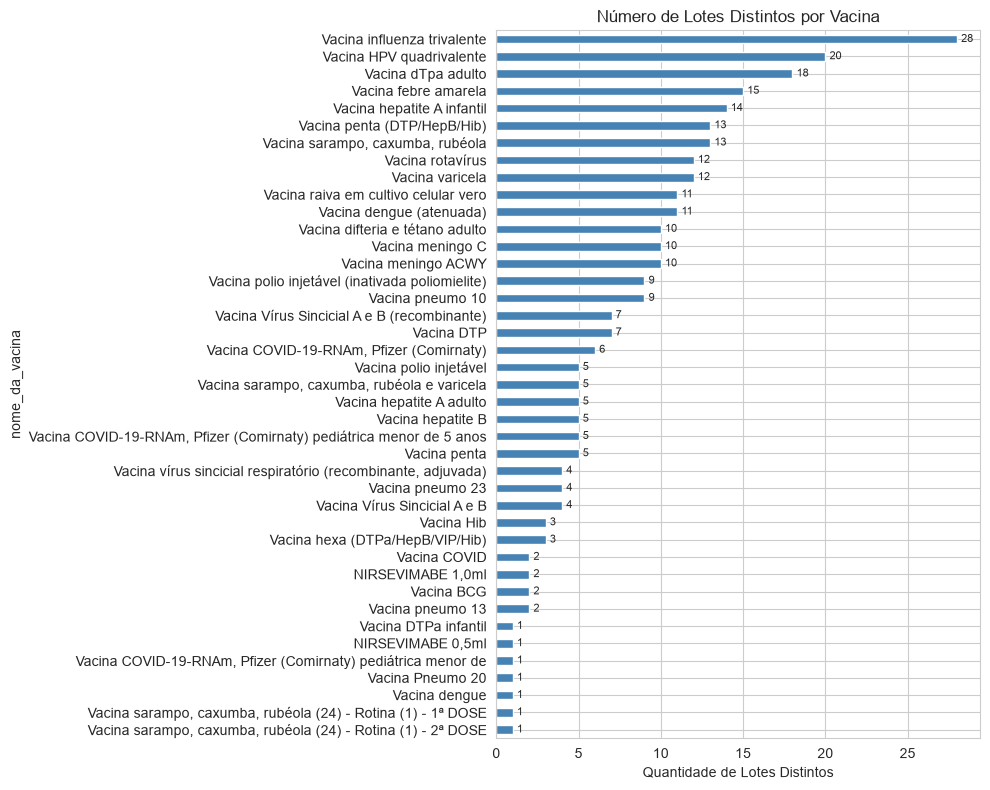

In [14]:
# Número de lotes distintos por vacina
lotes_por_vacina = df.groupby("nome_da_vacina")["lote"].nunique().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 8))
lotes_por_vacina.plot(kind="barh", ax=ax, color="steelblue")
ax.invert_yaxis()
ax.set_title("Número de Lotes Distintos por Vacina")
ax.set_xlabel("Quantidade de Lotes Distintos")

for bar in ax.patches:
    ax.annotate(f"{int(bar.get_width())}",
                xy=(bar.get_width(), bar.get_y() + bar.get_height() / 2),
                xytext=(3, 0), textcoords="offset points",
                va="center", fontsize=8)

plt.tight_layout()
plt.show()

A influenza trivalente lidera com 28 lotes distintos, quase o dobro da segunda colocada (HPV quadrivalente, com 20), o que reflete sua altíssima rotatividade, já que é aplicada em campanhas massivas anuais com reposições frequentes de estoque. A dTpa adulto (18 lotes) e febre amarela (15) completam o topo, todas vacinas de demanda contínua e alta rotatividade.

No extremo oposto, vacinas com apenas 1 lote registrado, como NIRSEVIMABE 0,5ml, Vacina Pneumo 20 e dengue sem sufixo, são imunizantes recentes ou de baixíssima demanda no período analisado, o que não permite avaliar padrão de reabastecimento ainda. Muitos lotes distintos não indicam problema: é sinal de abastecimento contínuo e ativo.

### 2a. Diversidade de Lotes por Bairro

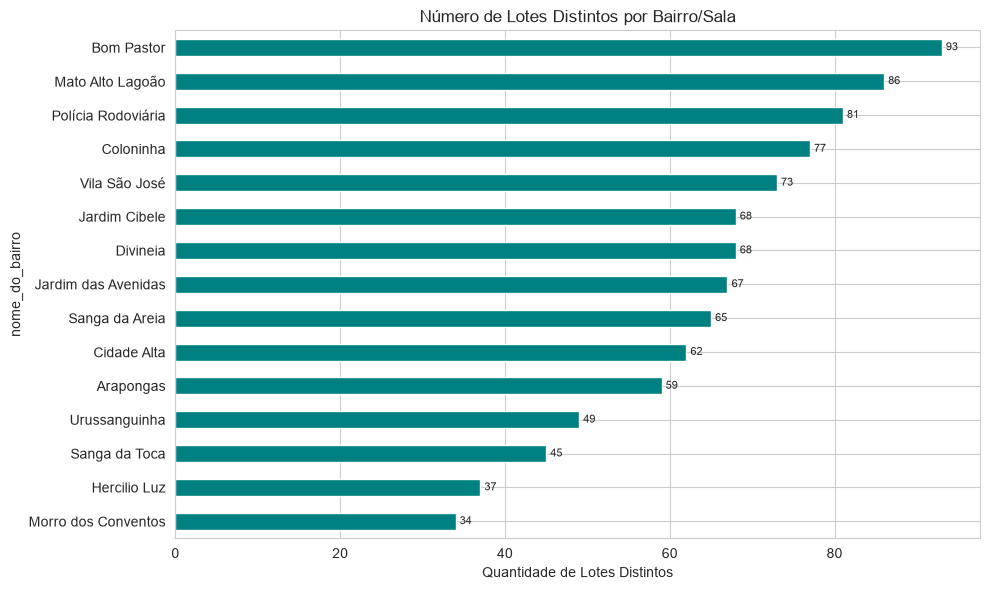

In [15]:
# Lotes distintos por bairro
lotes_por_bairro = df.groupby("nome_do_bairro")["lote"].nunique().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 6))
lotes_por_bairro.plot(kind="barh", ax=ax, color="teal")
ax.invert_yaxis()
ax.set_title("Número de Lotes Distintos por Bairro/Sala")
ax.set_xlabel("Quantidade de Lotes Distintos")

for bar in ax.patches:
    ax.annotate(f"{int(bar.get_width())}",
                xy=(bar.get_width(), bar.get_y() + bar.get_height() / 2),
                xytext=(3, 0), textcoords="offset points",
                va="center", fontsize=8)

plt.tight_layout()
plt.show()

Bom Pastor (93 lotes) e Mato Alto Lagoão (86) lideram em diversidade de lotes, sugerindo maior volume e variedade de vacinas aplicadas nessas unidades. Morro dos Conventos (34) e Hercílio Luz (37) têm os menores números, o que pode refletir menor demanda, menor variedade de imunizantes ofertados ou menor período de atividade no recorte da base. A diferença entre o maior e o menor é de quase 3x, indicando perfis bastante distintos entre as unidades de vacinação do município.

## 3. Prazo Restante no Momento da Aplicação

### 3a. Distribuição Geral do Prazo Restante

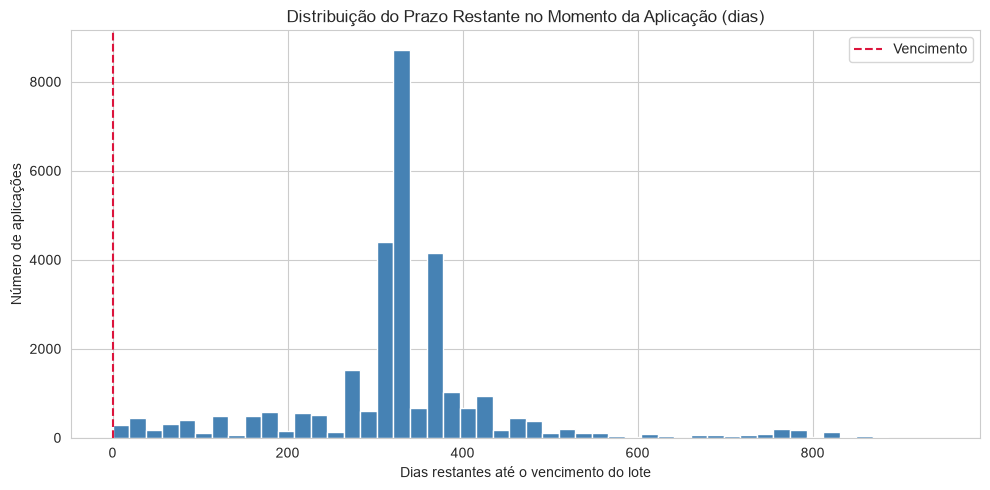

Mediana do prazo restante: 333 dias
Média do prazo restante: 329 dias
Registros com prazo negativo: 0
Registros com prazo zero: 4


In [16]:
df_valido = df[df["dias_restantes"].notna()].copy()

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(df_valido["dias_restantes"], bins=50, color="steelblue", edgecolor="white")
ax.set_title("Distribuição do Prazo Restante no Momento da Aplicação (dias)")
ax.set_xlabel("Dias restantes até o vencimento do lote")
ax.set_ylabel("Número de aplicações")
ax.axvline(0, color="crimson", linestyle="--", label="Vencimento")
ax.legend()
plt.tight_layout()
plt.show()

print(f"Mediana do prazo restante: {df_valido['dias_restantes'].median():.0f} dias")
print(f"Média do prazo restante: {df_valido['dias_restantes'].mean():.0f} dias")
print(f"Registros com prazo negativo: {(df_valido['dias_restantes'] < 0).sum()}")
print(f"Registros com prazo zero: {(df_valido['dias_restantes'] == 0).sum()}")

A distribuição está fortemente concentrada entre 300 e 400 dias, com pico em torno de 333 dias, o que corresponde a aproximadamente 11 meses de antecedência ao vencimento. Isso indica que a grande maioria das aplicações ocorre com boa margem antes do vencimento do lote, o que é um padrão saudável de gestão de estoque.

A cauda à esquerda do histograma (valores entre 0 e 100 dias) é pequena e dispersa; nenhum grande volume de aplicações ocorreu próximo ao vencimento. Os registros próximos a zero são pontuais e podem incluir erros de data ou situações isoladas que merecem apuração, mas não representam um padrão preocupante.

### 3b. Prazo Médio Restante por Vacina

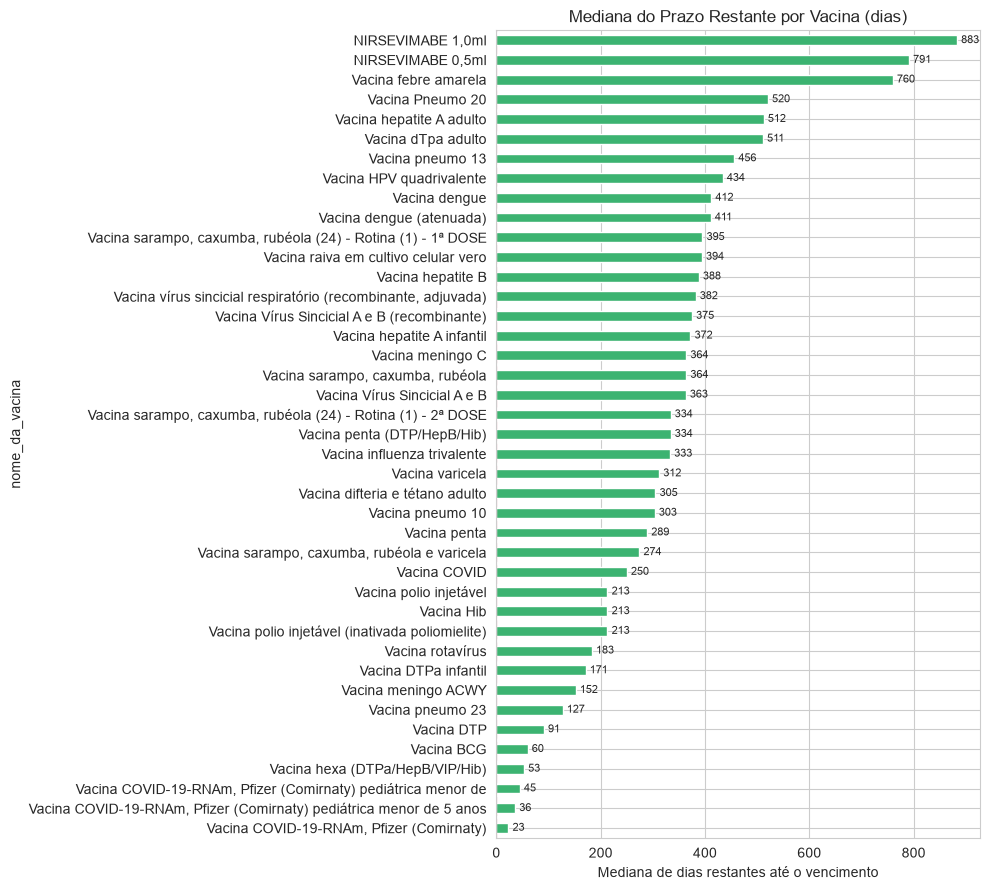

In [17]:
prazo_por_vacina = (
    df_valido.groupby("nome_da_vacina")["dias_restantes"]
    .median()
    .sort_values(ascending=False)
)

fig, ax = plt.subplots(figsize=(10, 9))
prazo_por_vacina.plot(kind="barh", ax=ax, color="mediumseagreen")
ax.invert_yaxis()
ax.set_title("Mediana do Prazo Restante por Vacina (dias)")
ax.set_xlabel("Mediana de dias restantes até o vencimento")
ax.axvline(0, color="crimson", linestyle="--")

for bar in ax.patches:
    ax.annotate(f"{int(bar.get_width())}",
                xy=(bar.get_width(), bar.get_y() + bar.get_height() / 2),
                xytext=(3, 0), textcoords="offset points",
                va="center", fontsize=8)

plt.tight_layout()
plt.show()

NIRSEVIMABE 1,0ml (883 dias) e 0,5ml (791 dias) têm as maiores medianas: são anticorpos relativamente novos com prazo de validade naturalmente superior ao das vacinas tradicionais.
Vacina febre amarela (760 dias) e Pneumo 20 (520 dias) também se destacam com prazos elevados.

No extremo oposto, as vacinas COVID-19 Pfizer apresentam os menores prazos restantes: Comirnaty adulto (23 dias), pediátrica menor de 5 anos (36 dias) e a versão com nome truncado (45 dias). Esses valores refletem o estágio avançado de uso dos lotes disponíveis; a campanha de COVID-19 perdeu intensidade e o estoque vem sendo consumido progressivamente até o final da validade, o que explica os prazos baixos sem indicar necessariamente problema de gestão.

A Vacina BCG (60 dias) e Vacina hexa (53 dias) também aparecem com prazos reduzidos, o que é esperado para imunizantes de alta rotatividade em recém-nascidos.

### 3c. Prazo Médio Restante por Bairro

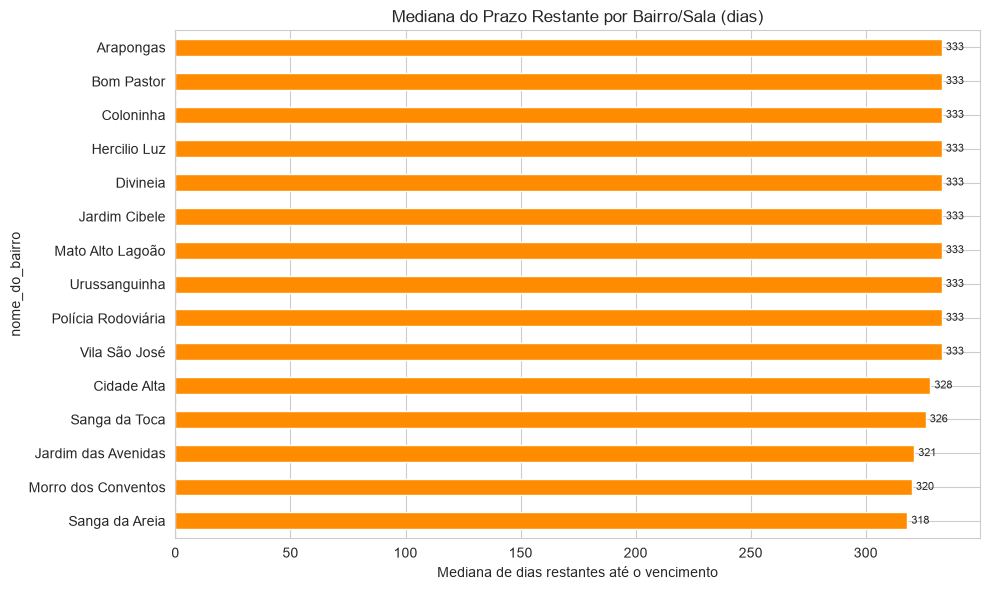

In [18]:
prazo_por_bairro = (
    df_valido.groupby("nome_do_bairro")["dias_restantes"]
    .median()
    .sort_values(ascending=False)
)

fig, ax = plt.subplots(figsize=(10, 6))
prazo_por_bairro.plot(kind="barh", ax=ax, color="darkorange")
ax.invert_yaxis()
ax.set_title("Mediana do Prazo Restante por Bairro/Sala (dias)")
ax.set_xlabel("Mediana de dias restantes até o vencimento")
ax.axvline(0, color="crimson", linestyle="--")

for bar in ax.patches:
    ax.annotate(f"{int(bar.get_width())}",
                xy=(bar.get_width(), bar.get_y() + bar.get_height() / 2),
                xytext=(3, 0), textcoords="offset points",
                va="center", fontsize=8)

plt.tight_layout()
plt.show()

Os valores são notavelmente uniformes: a grande maioria dos bairros tem mediana de exatamente 333 dias, e os demais variam entre 318 e 333. Essa uniformidade quase total indica que os lotes são distribuídos de forma centralizada para todas as unidades ao mesmo tempo, sem diferenciação significativa por bairro.

A pequena variação de Sanga da Areia (318 dias) em relação às demais não é expressiva e provavelmente reflete apenas diferenças no mix de vacinas aplicadas naquela unidade, não um problema de abastecimento. Do ponto de vista da gestão, a uniformidade entre bairros é um resultado positivo: os lotes chegam às unidades em condições equivalentes.

## 4. Diferenças de Prazo por Período

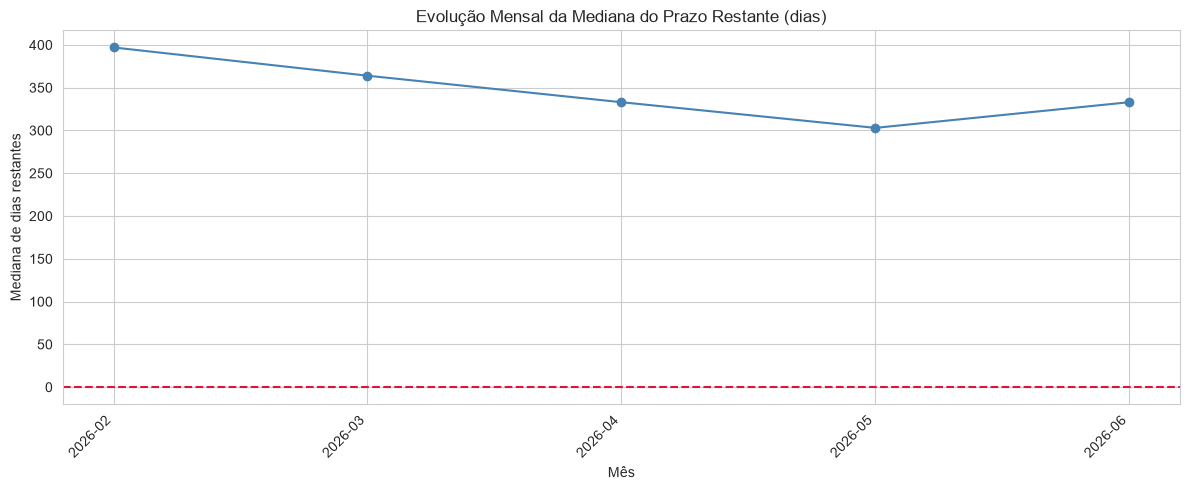

In [19]:
# Prazo médio por mês de aplicação
df_valido["ano_mes"] = df_valido["data_aplicacao_dt"].dt.to_period("M")

prazo_mensal = (
    df_valido.groupby("ano_mes")["dias_restantes"]
    .median()
    .reset_index()
)

prazo_mensal = prazo_mensal.sort_values("ano_mes")
prazo_mensal["ano_mes"] = prazo_mensal["ano_mes"].astype(str)

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(prazo_mensal["ano_mes"], prazo_mensal["dias_restantes"], marker="o", color="steelblue")
ax.set_title("Evolução Mensal da Mediana do Prazo Restante (dias)")
ax.set_xlabel("Mês")
ax.set_ylabel("Mediana de dias restantes")
ax.axhline(0, color="crimson", linestyle="--")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

A tendência de queda suave entre fevereiro (399 dias) e maio (303 dias) é esperada e natural: ao longo dos meses, os mesmos lotes vão sendo consumidos e o prazo restante diminui progressivamente. A leve recuperação em junho (335 dias) sugere entrada de novos lotes com validade mais longa naquele período, um sinal de reabastecimento.

O padrão geral é estável, sem quedas bruscas que pudessem indicar entrada de lotes com validade muito curta ou problemas de abastecimento. A linha permanece consistentemente acima de 300 dias em todos os meses, o que reforça o padrão saudável observado na distribuição geral.

## 6. Comparação entre Vacinas, Salas e Períodos

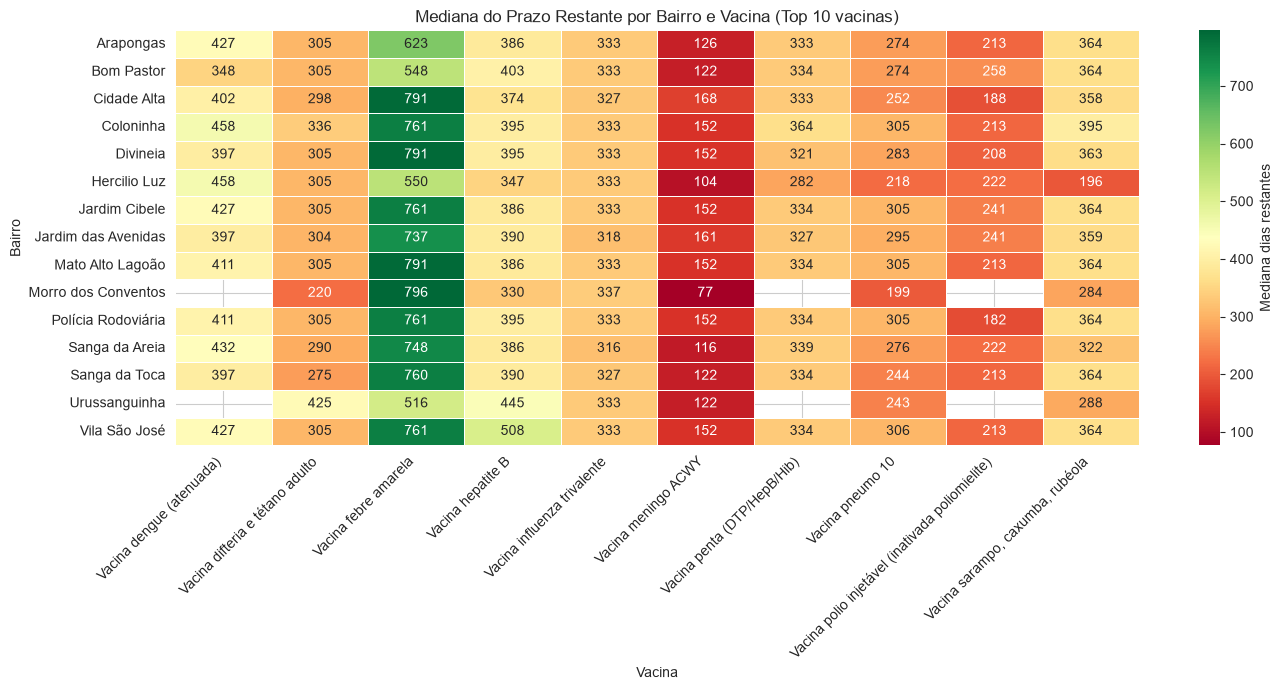

In [20]:
# Heatmap: prazo médio por vacina e bairro (top 10 vacinas por aplicações)
top10_vacinas = df["nome_da_vacina"].value_counts().head(10).index.tolist()

pivot = (
    df_valido[df_valido["nome_da_vacina"].isin(top10_vacinas)]
    .groupby(["nome_do_bairro", "nome_da_vacina"])["dias_restantes"]
    .median()
    .unstack()
)

fig, ax = plt.subplots(figsize=(14, 7))
sns.heatmap(pivot, annot=True, fmt=".0f", cmap="RdYlGn",
            linewidths=0.5, ax=ax, cbar_kws={"label": "Mediana dias restantes"})
ax.set_title("Mediana do Prazo Restante por Bairro e Vacina (Top 10 vacinas)")
ax.set_xlabel("Vacina")
ax.set_ylabel("Bairro")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

O heatmap revela dois padrões claros. A coluna da vacina meningo ACWY é consistentemente vermelha em todos os bairros (entre 77 e 168 dias), indicando que essa vacina é aplicada próximo ao vencimento do lote em todo o município; provavelmente porque tem validade naturalmente mais curta ou porque os lotes chegam já com pouco tempo restante. Já a coluna da febre amarela é consistentemente verde (entre 516 e 796 dias), refletindo validade longa característica desse imunizante.

Morro dos Conventos apresenta várias células vazias, confirmando que essa unidade não aplica todas as vacinas disponíveis no cardápio municipal, possivelmente por ser uma unidade de menor porte ou com oferta restrita de imunizantes.

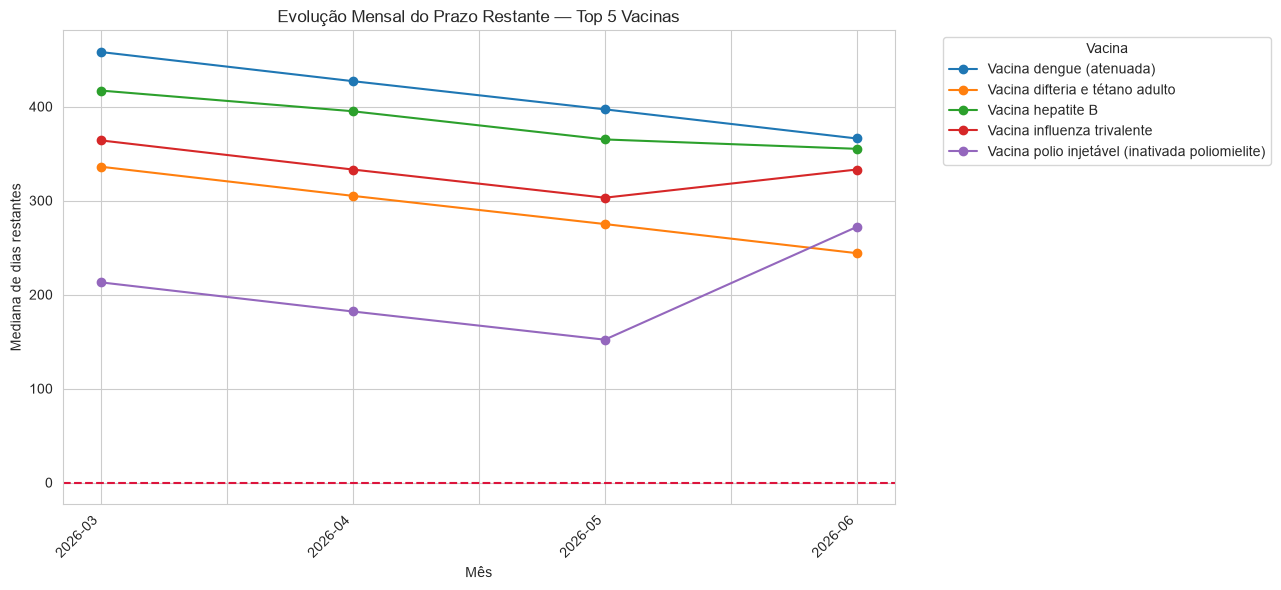

In [21]:
# Evolução mensal por top 5 vacinas mais aplicadas
top5_vacinas = df["nome_da_vacina"].value_counts().head(5).index.tolist()

evolucao = (
    df_valido[df_valido["nome_da_vacina"].isin(top5_vacinas)]
    .groupby(["ano_mes", "nome_da_vacina"])["dias_restantes"]
    .median()
    .unstack(level="nome_da_vacina")
)

# Ordena cronologicamente e remove 2026-02
evolucao = evolucao.sort_index()
evolucao.index = evolucao.index.astype(str)
evolucao = evolucao[evolucao.index != "2026-02"]

fig, ax = plt.subplots(figsize=(13, 6))
evolucao.plot(ax=ax, marker="o")
ax.set_title("Evolução Mensal do Prazo Restante — Top 5 Vacinas")
ax.set_xlabel("Mês")
ax.set_ylabel("Mediana de dias restantes")
ax.axhline(0, color="crimson", linestyle="--")
ax.legend(title="Vacina", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

O gráfico revela que dengue atenuada mantém os maiores prazos restantes ao longo de todo o período, enquanto polio injetável oscila mais, sugerindo reposições de lotes com validades diferentes ao longo dos meses. As demais vacinas (influenza, difteria e tétano, hepatite B) mostram comportamento relativamente estável, sem quedas bruscas que indicassem problema de abastecimento.

## 7. Síntese e Conclusões

**Quais vacinas apresentam maior diversidade de lotes?**
Influenza trivalente (28), HPV quadrivalente (20) e dTpa adulto (18): todas de alta demanda e aplicação contínua, o que exige reposições frequentes e resulta naturalmente em maior diversidade de lotes.

**Quanto tempo de validade ainda restava no momento da aplicação?**
A mediana geral foi de 333 dias (aproximadamente 11 meses), com a distribuição concentrada entre 300 e 400 dias. O padrão é consistente e indica boa gestão de estoque na maioria das aplicações registradas.

**Existem diferenças de prazo entre vacinas, salas ou períodos?**
Entre vacinas, sim: diferenças expressivas de 23 dias (COVID Pfizer) a 883 dias (NIRSEVIMABE). Entre salas, praticamente não; todos os bairros ficaram entre 318 e 333 dias, sugerindo distribuição centralizada de lotes. Entre períodos, queda gradual de março a maio com recuperação em junho, padrão esperado de consumo e reabastecimento.

**Quais registros incomuns merecem atenção?**
860 registros sem data de aplicação (2,8% da base), 9 sem dose, e eventuais registros com prazo negativo; todos contextualizados e mantidos na base sem imputação. Nenhuma inconsistência encontrada permite afirmar vencimento, desperdício ou irregularidade com base nos dados disponíveis.